# TP 2 — Deep Learning pour le NLP

**Cours NLP et Transformers — CY Tech · Séance 2**

---

## Objectif

Construire un pipeline complet sur le corpus **Tiny Shakespeare**, en quatre étapes (slide 65) :

1. nettoyage et prétraitement ;
2. représentation ;
3. comparaison entre modèles de **machine learning** (ML) et de **deep learning** (DL) ;
4. évaluation.

## Fil conducteur

On garde **la tâche et le jeu de test du TP 1** : prédire lequel des 5 personnages les plus bavards prononce une réplique (répliques d'au moins 5 mots). Une différence de score ne peut donc venir que du modèle, pas d'un changement de tâche.

La question du TP : **un réseau de neurones fait-il mieux qu'un modèle linéaire sur TF–IDF, et à quel prix ?**

## Modèles comparés

| Famille | Modèle | Ce qu'il reçoit | Slides |
|---|---|---|---|
| ML | Naive Bayes, régression logistique, SVM linéaire | vecteur TF–IDF creux (sans ordre des mots) | 31–33 |
| DL | MLP (perceptron multicouche) | le même vecteur TF–IDF | 49–54 |
| DL | Sac d'embeddings | moyenne d'embeddings de mots appris | 55 |
| DL | BiLSTM | séquence d'embeddings, lue dans les deux sens | 56–58 |
| DL | BiGRU | idem, avec une cellule à deux portes | 59 |

## Protocole : ce qui rend la comparaison honnête

- **Même découpage pour tous les modèles.** Le test est celui du TP 1 ; il ne sert qu'une fois, à la fin.
- **Même budget de réglage.** Un jeu de validation, extrait du train, sert à choisir les hyperparamètres des modèles ML et à arrêter l'entraînement des réseaux (*early stopping*).
- **Pas de fuite de données.** Vocabulaire, poids IDF et poids des classes sont calculés sur le train seul.
- **Plusieurs graines.** Un réseau dépend de son initialisation aléatoire : chaque modèle DL est entraîné 5 fois, et on rapporte moyenne ± écart-type.
- **Métrique principale : F1 macro**, comme au TP 1 (classes déséquilibrées, aucune classe prioritaire).

## Exécution

- **Avec un GPU** (Colab : `Exécution → Modifier le type d'exécution → GPU T4`) : quelques minutes.
- **Sans GPU** : 10 à 20 minutes, surtout à cause du BiLSTM et du BiGRU (environ une minute par entraînement sur un processeur de portable).

Les chiffres cités dans les analyses viennent d'une exécution complète sur CPU. Sur Colab, les scores des **réseaux** peuvent varier de 0,01 à 0,02 (autre matériel, autre version de PyTorch). Ceux des **modèles ML** sont identiques, et les conclusions ne changent pas.

## 0. Environnement

Tout est déjà installé dans Colab (PyTorch, scikit-learn, pandas, matplotlib).

In [1]:
import re
import copy
import time
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
pd.set_option("display.width", 140)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} — calcul sur : {device}")

PyTorch 2.11.0+cu130 — calcul sur : cuda


In [2]:
# Style commun des graphiques : fond clair, grille discrète, couleurs lisibles par les daltoniens
SURFACE, INK, INK2, MUTED, GRILLE, AXE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # bleu, orange, aqua
RAMPE_BLEUE = ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": INK2, "xtick.color": AXE, "ytick.color": AXE,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.labelcolor": INK2, "font.size": 10,
})

## 1. Charger le corpus et reconstruire la tâche du TP 1

Même corpus, même fonction de découpage en répliques et mêmes choix que le corrigé du TP 1 : les 5 locuteurs les plus fréquents, et seulement les répliques d'au moins 5 mots.

In [3]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")


def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte) — fonction du TP 1."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()

N_LOCUTEURS = 5
MIN_MOTS = 5
top_locuteurs = df["locuteur"].value_counts().head(N_LOCUTEURS).index

donnees = (
    df[df["locuteur"].isin(top_locuteurs) & (df["n_mots"] >= MIN_MOTS)]
    .loc[:, ["replique", "locuteur"]]
    .reset_index(drop=True)
)

print(f"Corpus : {len(texte):,} caractères, {len(df):,} répliques, {df['locuteur'].nunique()} locuteurs")
print(f"Tâche  : {len(donnees)} répliques, {N_LOCUTEURS} locuteurs\n")
print(donnees["locuteur"].value_counts().to_string())
print(f"\nRépliques en double dans la tâche : {donnees.duplicated('replique').sum()}")

Corpus : 1,115,394 caractères, 7,094 répliques, 297 locuteurs
Tâche  : 761 répliques, 5 locuteurs

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126

Répliques en double dans la tâche : 0


> **Lecture.** On retrouve exactement les 761 répliques du TP 1. Aucune réplique n'apparaît deux fois : il n'y a donc aucun risque qu'un même texte se retrouve à la fois dans le train et dans le test (slide 72, « dédupliquer avant le split »).

## 2. Découper en train, validation et test

Au TP 1, le découpage était en deux : train et test. Un réseau de neurones a besoin d'un **troisième jeu** :

- il s'entraîne en plusieurs passes (*époques*) et finit par mémoriser le train. Il faut un jeu qu'il ne voit pas pour savoir **quand s'arrêter** ;
- ses hyperparamètres (taux d'apprentissage, taille des couches…) doivent être choisis sans regarder le test.

On reproduit d'abord **exactement** le découpage du TP 1 (même appel, même graine), ce qui garantit un jeu de test identique. Puis on prélève 15 % du train pour la validation (slide 17).

In [4]:
# 1) Même appel que dans le TP 1 : le jeu de test est strictement identique.
X_trval, X_test, y_trval, y_test = train_test_split(
    donnees["replique"], donnees["locuteur"],
    test_size=0.20, stratify=donnees["locuteur"], random_state=RANDOM_STATE,
)

# 2) On prélève 15 % du reste pour la validation (réglages + arrêt précoce).
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval,
    test_size=0.15, stratify=y_trval, random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)}   validation : {len(X_val)}   test : {len(X_test)}\n")
print("Proportion de chaque classe (vérification de la stratification) :")
print(pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3).to_string())

# Les réseaux attendent des étiquettes entières 0..K-1
encodeur = LabelEncoder().fit(y_train)
CLASSES = encodeur.classes_
K = len(CLASSES)
ytr, yva, yte = (encodeur.transform(y) for y in (y_train, y_val, y_test))

train : 516   validation : 92   test : 153

Proportion de chaque classe (vérification de la stratification) :
                train  validation   test
locuteur                                
GLOUCESTER      0.256       0.261  0.261
DUKE VINCENTIO  0.217       0.217  0.216
ROMEO           0.186       0.185  0.183
PETRUCHIO       0.174       0.174  0.176
MENENIUS        0.167       0.163  0.163


> **Le prix de la validation.** Le train passe de 608 à 516 exemples. Les scores ML de ce TP seront donc légèrement différents de ceux du TP 1 (F1 macro 0,669 pour la régression logistique). En contrepartie, plus aucun réglage ne regarde le test : la réserve formulée à la fin du corrigé du TP 1 est levée.

## 3. Nettoyage et prétraitement

Les deux familles de modèles ne consomment pas le texte de la même façon :

- les modèles **ML** et le **MLP** reçoivent un vecteur TF–IDF : `TfidfVectorizer` gère lui-même la casse et le découpage en mots (réglages du TP 1) ;
- les réseaux **à embeddings** (sac d'embeddings, BiLSTM, BiGRU) reçoivent une **séquence d'identifiants entiers**. On écrit donc nous-mêmes la tokenisation, le vocabulaire et le padding.

| Décision | Choix | Justification |
|---|---|---|
| Unité | le mot | le découpage en sous-mots (slide 9) sert surtout aux modèles pré-entraînés sur de grands corpus ; ici, un vocabulaire de mots appris sur 500 répliques suffit |
| Casse | minuscules | « Love » et « love » doivent partager le même vecteur : avec si peu de données, on ne peut pas apprendre chaque mot deux fois |
| Ponctuation | on garde `!` et `?` | ils portent du registre (exclamations, questions) ; le reste de la ponctuation est retiré |
| Apostrophes | conservées dans le mot (`know't`, `o'er`) | ce sont des marques du style élisabéthain |
| Mots vides | **conservés** | `thou`, `thy`, `my lord` signent un registre (leçon du TP 1) ; et pour un réseau récurrent, l'ordre et les mots grammaticaux font partie du signal |
| Lemmatisation, stemming | non | réduire `thou` / `thee` / `thy` à une seule forme effacerait des marques de style |

### 3.1 Tokeniser

In [5]:
MOTIF_TOKEN = re.compile(r"[a-z]+(?:'[a-z]+)*|[!?]")


def tokeniser(texte: str) -> list:
    """Minuscules, mots (apostrophes internes comprises) et ponctuation expressive ! ?"""
    return MOTIF_TOKEN.findall(texte.lower())


for r in X_train.iloc[:3]:
    print(f"« {r[:100]}{'…' if len(r) > 100 else ''} »")
    print("  ->", tokeniser(r)[:18], "\n")

« Well, sir, in brief, the gown is not for me. »
  -> ['well', 'sir', 'in', 'brief', 'the', 'gown', 'is', 'not', 'for', 'me'] 

« I'll teach you how you shall arraign your conscience, And try your penitence, if it be sound, Or hol… »
  -> ["i'll", 'teach', 'you', 'how', 'you', 'shall', 'arraign', 'your', 'conscience', 'and', 'try', 'your', 'penitence', 'if', 'it', 'be', 'sound', 'or'] 

« More light and light; more dark and dark our woes! »
  -> ['more', 'light', 'and', 'light', 'more', 'dark', 'and', 'dark', 'our', 'woes', '!'] 



### 3.2 Construire le vocabulaire — sur le train seulement

Le vocabulaire est un composant **appris** : il est construit sur le train seul, comme l'IDF au TP 1. Les mots vus une seule fois sont envoyés vers le token `<unk>` (inconnu) : un vecteur appris à partir d'un unique exemple ne généralise pas. C'est la même logique que `min_df=2` au TP 1. L'identifiant 0 est réservé au padding `<pad>`.

In [6]:
PAD, UNK = 0, 1
MIN_FREQ = 2


def construire_vocab(textes, tok=tokeniser, min_freq=MIN_FREQ):
    """Renvoie (mot -> identifiant, liste des mots). 0 = <pad>, 1 = <unk>."""
    compteur = Counter(m for t in textes for m in tok(t))
    itos = ["<pad>", "<unk>"] + [m for m, c in compteur.most_common() if c >= min_freq]
    return {m: i for i, m in enumerate(itos)}, itos


stoi, itos = construire_vocab(X_train)


def taux_inconnus(textes):
    toks = [m for t in textes for m in tokeniser(t)]
    return sum(m not in stoi for m in toks) / len(toks)


print(f"Vocabulaire : {len(itos):,} entrées (dont <pad> et <unk>)")
print(f"Tokens les plus fréquents : {itos[2:20]}")
print("\nPart des tokens remplacés par <unk> :")
for nom, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"  {nom:<10} {taux_inconnus(X):.1%}")

Vocabulaire : 1,387 entrées (dont <pad> et <unk>)
Tokens les plus fréquents : ['the', 'and', 'to', 'i', 'you', 'of', 'a', 'that', 'my', 'in', '?', 'is', 'not', 'for', 'me', '!', 'with', 'it']

Part des tokens remplacés par <unk> :
  train      11.1%
  validation 18.4%
  test       16.1%


> **Lecture.**
>
> - Le vocabulaire est **petit** : environ 1 400 mots retenus pour 516 répliques.
> - Même sur le train, 11 % des tokens sont des mots vus une seule fois, remplacés par `<unk>`.
> - Sur la validation et le test, 16 à 18 % des tokens sont **inconnus**. Pour ces mots, un réseau à embeddings ne dispose d'aucun vecteur appris : un mot sur six est invisible pour lui.
>
> C'est la limite d'un vocabulaire appris sur si peu de texte. Elle justifie deux outils du cours Transformers : les **tokenizers en sous-mots**, qui découpent un mot inconnu en morceaux connus, et les **embeddings pré-entraînés** sur de très grands corpus. TF–IDF a la même limite : un mot absent du train n'a pas de colonne.

### 3.3 Choisir une longueur maximale

Un mini-batch est un tenseur rectangulaire : toutes les séquences doivent avoir la même longueur `MAX_LEN`. Les plus courtes sont complétées par `<pad>`, les plus longues sont tronquées.

Longueur en tokens — médiane 18, moyenne 36.4, max 589
MAX_LEN = 95e centile = 116 tokens  ->  5.0% des répliques tronquées


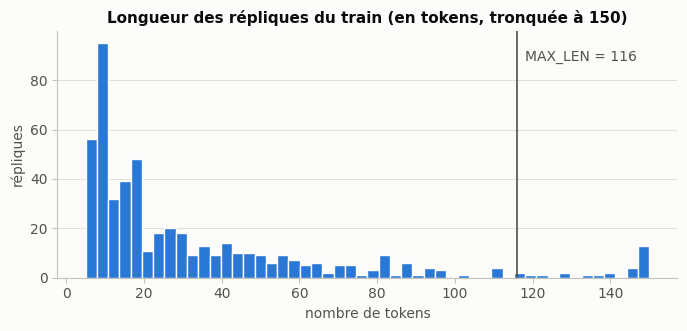

In [7]:
longueurs = np.array([len(tokeniser(t)) for t in X_train])
MAX_LEN = int(np.percentile(longueurs, 95))

print(f"Longueur en tokens — médiane {np.median(longueurs):.0f}, moyenne {longueurs.mean():.1f}, max {longueurs.max()}")
print(f"MAX_LEN = 95e centile = {MAX_LEN} tokens  ->  {np.mean(longueurs > MAX_LEN):.1%} des répliques tronquées")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(np.clip(longueurs, 0, 150), bins=50, color=SERIES[0], edgecolor=SURFACE, linewidth=1)
ax.axvline(MAX_LEN, color=INK2, linewidth=1.2)
ax.annotate(f"MAX_LEN = {MAX_LEN}", xy=(MAX_LEN, ax.get_ylim()[1] * 0.88),
            xytext=(6, 0), textcoords="offset points", color=INK2)
ax.set_title("Longueur des répliques du train (en tokens, tronquée à 150)")
ax.set_xlabel("nombre de tokens")
ax.set_ylabel("répliques")
ax.grid(axis="x", visible=False)
plt.show()

**Pourquoi le 95e centile ?** Remplir toutes les séquences jusqu'à la plus longue tirade multiplierait le calcul pour quelques répliques. En tronquant au 95e centile, 5 % des répliques perdent leur fin, mais leur début contient déjà largement de quoi identifier le locuteur. Le padding, lui, ne coûte rien en qualité : il est **masqué** (moyenne qui l'exclut, `pack_padded_sequence` pour les RNN), le réseau ne le lit jamais.

### 3.4 Encoder : texte → identifiants

In [8]:
def encoder_sequences(textes, stoi, max_len=MAX_LEN, tok=tokeniser):
    """Texte -> (identifiants complétés par du padding, longueur réelle de chaque séquence)."""
    ids = torch.full((len(textes), max_len), PAD, dtype=torch.long)
    lens = torch.zeros(len(textes), dtype=torch.long)
    for i, t in enumerate(textes):
        seq = [stoi.get(m, UNK) for m in tok(t)][:max_len] or [UNK]
        ids[i, :len(seq)] = torch.tensor(seq)
        lens[i] = len(seq)
    return ids, lens


ids_tr, len_tr = encoder_sequences(X_train, stoi)

exemple = X_train.iloc[0]
print("Texte        :", exemple[:80])
print("Tokens       :", tokeniser(exemple)[:12])
print("Identifiants :", ids_tr[0, :12].tolist(), "...")
print("Décodage     :", [itos[i] for i in ids_tr[0, :12].tolist()])
print(f"\nids_tr : {tuple(ids_tr.shape)} = (exemples, MAX_LEN)      len_tr : {tuple(len_tr.shape)}")

Texte        : Well, sir, in brief, the gown is not for me.
Tokens       : ['well', 'sir', 'in', 'brief', 'the', 'gown', 'is', 'not', 'for', 'me']
Identifiants : [48, 103, 11, 497, 2, 864, 13, 14, 15, 16, 0, 0] ...
Décodage     : ['well', 'sir', 'in', 'brief', 'the', 'gown', 'is', 'not', 'for', 'me', '<pad>', '<pad>']

ids_tr : (516, 116) = (exemples, MAX_LEN)      len_tr : (516,)


## 4. Représentation

### 4.1 TF–IDF — pour les modèles ML et le MLP

Mêmes réglages que le TP 1 (bigrammes, `min_df=2`, `max_df=0.8`, `sublinear_tf`, pas de liste de mots vides), ajustés sur le train seul.

In [9]:
def nouveau_tfidf(**options):
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.8,
                           sublinear_tf=True, **options)


vectoriseur = nouveau_tfidf()
Xtr_tfidf = vectoriseur.fit_transform(X_train)   # fit sur le train uniquement
Xva_tfidf = vectoriseur.transform(X_val)
Xte_tfidf = vectoriseur.transform(X_test)

print(f"TF–IDF train : {Xtr_tfidf.shape}  ->  {Xtr_tfidf.nnz / np.prod(Xtr_tfidf.shape):.2%} de valeurs non nulles")

TF–IDF train : (516, 2958)  ->  1.11% de valeurs non nulles


### 4.2 Embeddings — pour les réseaux

Un embedding est une **matrice apprise** $E \in \mathbb{R}^{|V| \times d}$ : chaque identifiant de token sélectionne une ligne (slide 55). Le réseau ajuste ces lignes par rétropropagation, comme n'importe quel autre poids.

- Le **sac d'embeddings** fait la moyenne des vecteurs de la réplique. Comme TF–IDF, il ignore l'ordre des mots, mais il travaille dans un espace **dense et de petite dimension** (64 au lieu de plusieurs milliers).
- Le **BiLSTM / BiGRU** lit la séquence mot après mot (slide 56). Son état caché $h_t$ dépend de tous les mots déjà lus : c'est une **représentation contextualisée**. La ligne de $E$, elle, est la même pour un mot partout où il apparaît (embedding statique, slide 14). *Bidirectionnel* : une lecture de gauche à droite et une de droite à gauche, dont on concatène les états finaux (slide 60).

Vérifions les formes des tenseurs sur un mini-batch de 4 répliques, comme dans les TP Transformers :

In [10]:
torch.manual_seed(0)
d_emb, d_cache = 100, 64
emb = nn.Embedding(len(itos), d_emb, padding_idx=PAD)
lstm = nn.LSTM(d_emb, d_cache, batch_first=True, bidirectional=True)

xb = ids_tr[:4]
e = emb(xb)
sorties, (h_n, c_n) = lstm(e)

print(f"identifiants          xb : {tuple(xb.shape)}        (B, T)")
print(f"embeddings         E[xb] : {tuple(e.shape)}   (B, T, d_emb)")
print(f"états cachés h_1 … h_T   : {tuple(sorties.shape)}   (B, T, 2 × d_cache) : un vecteur par position et par sens")
print(f"état final h_n           : {tuple(h_n.shape)}       (2 sens, B, d_cache)")
print(f"\nParamètres de l'embedding : {emb.weight.numel():,} = {len(itos):,} mots × {d_emb} dimensions")

identifiants          xb : (4, 116)        (B, T)
embeddings         E[xb] : (4, 116, 100)   (B, T, d_emb)
états cachés h_1 … h_T   : (4, 116, 128)   (B, T, 2 × d_cache) : un vecteur par position et par sens
état final h_n           : (2, 4, 64)       (2 sens, B, d_cache)

Paramètres de l'embedding : 138,700 = 1,387 mots × 100 dimensions


## 5. Modèles ML — la référence à battre

On reprend les trois modèles du TP 1. Cette fois, leur hyperparamètre de régularisation est choisi sur la **validation** et non en regardant le test. Les réseaux auront droit au même traitement (arrêt précoce sur la validation).

In [11]:
grilles = {
    "Naive Bayes": (lambda v: MultinomialNB(alpha=v), "alpha", [0.05, 0.1, 0.3, 0.5, 1.0]),
    "Régression logistique": (
        lambda v: LogisticRegression(C=v, max_iter=5000, class_weight="balanced",
                                     random_state=RANDOM_STATE),
        "C", [0.5, 1, 2, 5, 10, 20]),
    "SVM linéaire": (
        lambda v: LinearSVC(C=v, class_weight="balanced", random_state=RANDOM_STATE),
        "C", [0.03, 0.1, 0.3, 1, 3]),
}

modeles_ml, durees_ml, lignes = {}, {}, []
for nom, (fabrique, param, valeurs) in grilles.items():
    scores = {v: f1_score(yva, fabrique(v).fit(Xtr_tfidf, ytr).predict(Xva_tfidf), average="macro")
              for v in valeurs}
    v_retenu = max(scores, key=scores.get)
    t0 = time.perf_counter()
    modeles_ml[nom] = fabrique(v_retenu).fit(Xtr_tfidf, ytr)
    durees_ml[nom] = time.perf_counter() - t0
    lignes.append({"modèle": nom, "réglage retenu": f"{param} = {v_retenu}",
                   "F1 macro (validation)": scores[v_retenu],
                   "grille testée (valeur : F1 validation)": "   ".join(f"{v} : {s:.2f}" for v, s in scores.items())})

modeles_ml["Baseline (classe majoritaire)"] = DummyClassifier(strategy="most_frequent").fit(Xtr_tfidf, ytr)

selection_ml = pd.DataFrame(lignes).set_index("modèle")
meilleur_ml = selection_ml["F1 macro (validation)"].idxmax()
print(f"Meilleur modèle ML sur la validation : {meilleur_ml}\n")
selection_ml.round(3)

Meilleur modèle ML sur la validation : Naive Bayes



,réglage retenu,F1 macro (validation),grille testée (valeur : F1 validation)
modèle,,,
Naive Bayes,alpha = 0.05,0.623,0.05 : 0.62 0.1 : 0.59 0.3 : 0.60 0.5 : ...
Régression logistique,C = 5,0.618,0.5 : 0.60 1 : 0.59 2 : 0.61 5 : 0.62 ...
SVM linéaire,C = 1,0.613,0.03 : 0.55 0.1 : 0.59 0.3 : 0.60 1 : 0....


## 6. Modèles de deep learning

### 6.1 Les quatre architectures

| Modèle | Calcul | Ordre des mots ? |
|---|---|---|
| **MLP** | TF–IDF → couche cachée de 256 neurones (ReLU) → 5 scores | non |
| **Sac d'embeddings** | moyenne des embeddings (d = 64) de la réplique → 5 scores | non |
| **BiLSTM** | embeddings (d = 100) → LSTM bidirectionnel (64 par sens) → états finaux concaténés → 5 scores | **oui** |
| **BiGRU** | idem avec une cellule GRU (2 portes au lieu de 3, slide 59) | **oui** |

Chaque modèle se termine par une couche linéaire qui produit un **score (logit) par locuteur** ; la softmax est incluse dans la loss (`CrossEntropyLoss`). Le *dropout* (désactivation aléatoire de neurones pendant l'entraînement) sert de régularisation (slide 26).

In [12]:
class MLP(nn.Module):
    """TF–IDF -> couche cachée ReLU -> scores des classes (slide 50)."""

    def __init__(self, n_entree, n_cache=256, n_classes=K, dropout=0.5):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Linear(n_entree, n_cache), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_cache, n_classes),
        )

    def forward(self, x):
        return self.reseau(x)


class SacEmbeddings(nn.Module):
    """Moyenne des embeddings des tokens (padding exclu) -> couche linéaire."""

    def __init__(self, taille_vocab, d_emb=64, n_classes=K, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(taille_vocab, d_emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.sortie = nn.Linear(d_emb, n_classes)

    def forward(self, ids, longueurs):
        e = self.emb(ids)                                    # (B, T, d)
        masque = (ids != PAD).unsqueeze(-1).float()          # (B, T, 1) : 1 = vrai token
        moyenne = (e * masque).sum(1) / masque.sum(1).clamp(min=1)
        return self.sortie(self.drop(moyenne))


class RNNBidirectionnel(nn.Module):
    """Embeddings -> LSTM ou GRU bidirectionnel -> derniers états des deux sens -> classes."""

    def __init__(self, taille_vocab, cellule="lstm", d_emb=100, d_cache=64, n_classes=K,
                 dropout_emb=0.3, dropout=0.5):
        super().__init__()
        self.emb = nn.Embedding(taille_vocab, d_emb, padding_idx=PAD)
        rnn = nn.LSTM if cellule == "lstm" else nn.GRU
        self.rnn = rnn(d_emb, d_cache, batch_first=True, bidirectional=True)
        self.drop_emb, self.drop = nn.Dropout(dropout_emb), nn.Dropout(dropout)
        self.sortie = nn.Linear(2 * d_cache, n_classes)

    def forward(self, ids, longueurs):
        e = self.drop_emb(self.emb(ids))
        # pack : le RNN s'arrête au vrai dernier token et ne lit jamais le padding
        paquet = pack_padded_sequence(e, longueurs.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(paquet)
        if isinstance(h, tuple):          # le LSTM renvoie (h_n, c_n), le GRU seulement h_n
            h = h[0]
        h = torch.cat([h[-2], h[-1]], dim=1)   # (B, 2 × d_cache) : lecture avant + lecture arrière
        return self.sortie(self.drop(h))


# Hyperparamètres d'optimisation (taux d'apprentissage, nombre max d'époques, patience de l'arrêt précoce)
ARCHITECTURES = {
    "MLP (TF–IDF)":     dict(entree="tfidf", lr=1e-3, epoques=60, patience=10),
    "Sac d'embeddings": dict(entree="seq", lr=5e-3, epoques=100, patience=15),
    "BiLSTM":           dict(entree="seq", cellule="lstm", lr=3e-3, epoques=60, patience=10),
    "BiGRU":            dict(entree="seq", cellule="gru", lr=3e-3, epoques=60, patience=10),
}


def fabriquer(nom, P):
    """Crée un réseau neuf, dimensionné sur le vocabulaire / le TF–IDF préparés dans P."""
    cfg = ARCHITECTURES[nom]
    if cfg["entree"] == "tfidf":
        return MLP(P["n_entree"])
    if nom == "Sac d'embeddings":
        return SacEmbeddings(P["taille_vocab"])
    return RNNBidirectionnel(P["taille_vocab"], cfg["cellule"])


def n_parametres(modele):
    return sum(p.numel() for p in modele.parameters() if p.requires_grad)

### 6.2 Préparer les données et la boucle d'entraînement

La fonction `preparer` regroupe tout ce qui **s'apprend sur le train** : TF–IDF, vocabulaire et poids des classes. Elle sera réutilisée telle quelle dans les expériences de la partie 8 (autre sous-ensemble de train, autre vocabulaire) : c'est ce qui rend la fuite de données impossible par construction, comme le `Pipeline` scikit-learn du TP 1.

La boucle d'entraînement suit les quatre temps du cours (slide 54) : **forward**, **loss**, **backward**, **mise à jour**. On y ajoute :

- une **loss pondérée par classe** (`class_weight="balanced"`, slide 70) : une erreur sur un locuteur rare compte un peu plus ;
- un **écrêtage du gradient** (*gradient clipping*), réponse classique à l'explosion du gradient dans les RNN (slide 57) ;
- l'**arrêt précoce** : après chaque époque, on mesure le F1 macro de validation, on garde les poids de la meilleure époque, et on s'arrête quand il ne progresse plus depuis `patience` époques (slide 26).

In [13]:
def jeu_tfidf(X, y):
    return TensorDataset(torch.tensor(X.toarray(), dtype=torch.float32), torch.tensor(y))


def jeu_seq(ids, lens, y):
    return TensorDataset(ids, lens, torch.tensor(y))


def preparer(X_tr, y_tr, tok=tokeniser, mots_exclus=None):
    """Ajuste sur X_tr tout ce qui s'apprend (TF–IDF, vocabulaire, poids des classes),
    puis encode train, validation et test avec ces composants figés."""
    vec = nouveau_tfidf(stop_words=mots_exclus).fit(X_tr)
    stoi_, itos_ = construire_vocab(X_tr, tok)
    sources = {"train": (X_tr, y_tr), "val": (X_val, yva), "test": (X_test, yte)}
    return {
        "vec": vec, "stoi": stoi_, "itos": itos_,
        "tfidf": {s: jeu_tfidf(vec.transform(X), y) for s, (X, y) in sources.items()},
        "seq": {s: jeu_seq(*encoder_sequences(X, stoi_, tok=tok), y) for s, (X, y) in sources.items()},
        "taille_vocab": len(itos_), "n_entree": len(vec.vocabulary_),
        "poids": torch.tensor(compute_class_weight("balanced", classes=np.arange(K), y=y_tr),
                              dtype=torch.float32),
    }


def predire(modele, jeu, fn_perte=None):
    """Prédictions (et perte moyenne si fn_perte est fourni) sur un jeu complet, sans gradient."""
    modele.eval()
    preds, perte, n = [], 0.0, 0
    with torch.no_grad():
        for *entrees, y in DataLoader(jeu, batch_size=512):
            entrees, y = [t.to(device) for t in entrees], y.to(device)
            logits = modele(*entrees)
            if fn_perte is not None:
                perte += fn_perte(logits, y).item() * len(y)
            n += len(y)
            preds.append(logits.argmax(1).cpu())
    return torch.cat(preds).numpy(), perte / n


def entrainer(modele, jeu_train, jeu_val, lr, epoques, patience, graine, poids,
              taille_batch=32, weight_decay=1e-2, clip=1.0):
    """Entraîne avec AdamW et arrêt précoce sur le F1 macro de validation."""
    modele = modele.to(device)
    melange = torch.Generator().manual_seed(graine)
    chargeur = DataLoader(jeu_train, batch_size=taille_batch, shuffle=True, generator=melange)
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=weight_decay)
    fn_perte = nn.CrossEntropyLoss(weight=poids.to(device))
    y_val = jeu_val.tensors[-1].numpy()

    historique, meilleur, attente = [], {"f1": -1.0}, 0
    for epoque in range(1, epoques + 1):
        modele.train()
        somme, n = 0.0, 0
        for *entrees, y in chargeur:
            entrees, y = [t.to(device) for t in entrees], y.to(device)
            optimiseur.zero_grad(set_to_none=True)
            perte = fn_perte(modele(*entrees), y)                   # 1. forward  2. loss
            perte.backward()                                         # 3. backward : gradients
            nn.utils.clip_grad_norm_(modele.parameters(), clip)
            optimiseur.step()                                        # 4. mise à jour des poids
            somme, n = somme + perte.item() * len(y), n + len(y)

        pred_val, perte_val = predire(modele, jeu_val, fn_perte)
        f1_val = f1_score(y_val, pred_val, average="macro")
        historique.append({"époque": epoque, "perte train": somme / n,
                           "perte validation": perte_val, "F1 validation": f1_val})

        if f1_val > meilleur["f1"]:
            meilleur = {"f1": f1_val, "époque": epoque, "poids": copy.deepcopy(modele.state_dict())}
            attente = 0
        else:
            attente += 1
            if attente >= patience:
                break

    modele.load_state_dict(meilleur["poids"])     # on revient à la meilleure époque
    return modele, pd.DataFrame(historique), meilleur["époque"]


def entrainer_dl(nom, P, graine):
    """Un entraînement complet d'une architecture, pour une graine donnée."""
    cfg = ARCHITECTURES[nom]
    torch.manual_seed(graine)          # initialisation des poids et du dropout
    jeux = P[cfg["entree"]]
    return entrainer(fabriquer(nom, P), jeux["train"], jeux["val"], lr=cfg["lr"],
                     epoques=cfg["epoques"], patience=cfg["patience"], graine=graine, poids=P["poids"])


P = preparer(X_train, ytr)
print(f"Vocabulaire : {P['taille_vocab']:,} mots   TF–IDF : {P['n_entree']:,} colonnes")
print(f"Poids des classes : {dict(zip(CLASSES, P['poids'].numpy().round(2)))}\n")

print(f"{'modèle':<18}{'paramètres':>12}{'paramètres par exemple de train':>34}")
for nom in ARCHITECTURES:
    n = n_parametres(fabriquer(nom, P))
    print(f"{nom:<18}{n:>12,}{n / len(X_train):>34,.0f}")

Vocabulaire : 1,387 mots   TF–IDF : 2,958 colonnes
Poids des classes : {'DUKE VINCENTIO': np.float32(0.92), 'GLOUCESTER': np.float32(0.78), 'MENENIUS': np.float32(1.2), 'PETRUCHIO': np.float32(1.15), 'ROMEO': np.float32(1.08)}

modèle              paramètres   paramètres par exemple de train
MLP (TF–IDF)           758,789                             1,471
Sac d'embeddings        89,093                               173
BiLSTM                 224,337                               435
BiGRU                  203,089                               394


> **Lecture.** Naive Bayes et la régression logistique ont 14 795 paramètres, soit environ **29 par exemple** d'entraînement. Les réseaux en ont 6 à 50 fois plus : entre 173 et 1 471 par exemple. L'embedding du BiLSTM compte à lui seul 138 700 paramètres.
>
> Avec autant de liberté pour si peu d'exemples, un réseau peut apprendre le train **par cœur**. La régularisation (dropout, weight decay) et surtout l'**arrêt précoce** sont donc indispensables (slide 26). Les courbes ci-dessous le confirment.

### 6.3 Entraîner — 4 architectures × 5 graines

In [14]:
GRAINES = [0, 1, 2, 3, 4]
modeles_dl, historiques, resume = {}, {}, []

for nom in ARCHITECTURES:
    for graine in GRAINES:
        t0 = time.perf_counter()
        modele, hist, ep = entrainer_dl(nom, P, graine)
        modeles_dl[(nom, graine)] = modele
        if graine == 0:
            historiques[nom] = hist
        resume.append({"modèle": nom, "graine": graine, "meilleure époque": ep,
                       "époques jouées": len(hist), "F1 validation": hist["F1 validation"].max(),
                       "durée (s)": time.perf_counter() - t0})
    r = pd.DataFrame([x for x in resume if x["modèle"] == nom])
    print(f"{nom:<18} F1 validation = {r['F1 validation'].mean():.3f} ± {r['F1 validation'].std():.3f}"
          f"   meilleure époque (médiane) : {r['meilleure époque'].median():.0f}"
          f"   {r['durée (s)'].mean():.1f} s par entraînement")

resume = pd.DataFrame(resume)
meilleur_dl = resume.groupby("modèle")["F1 validation"].mean().idxmax()
print(f"\nMeilleur réseau sur la validation : {meilleur_dl}")

MLP (TF–IDF)       F1 validation = 0.665 ± 0.008   meilleure époque (médiane) : 7   1.9 s par entraînement
Sac d'embeddings   F1 validation = 0.592 ± 0.019   meilleure époque (médiane) : 42   2.6 s par entraînement
BiLSTM             F1 validation = 0.403 ± 0.035   meilleure époque (médiane) : 17   6.0 s par entraînement
BiGRU              F1 validation = 0.405 ± 0.025   meilleure époque (médiane) : 14   4.6 s par entraînement

Meilleur réseau sur la validation : MLP (TF–IDF)


### 6.4 Courbes d'apprentissage

Pour chaque réseau (graine 0) : en haut, la perte sur le train et sur la validation ; en bas, le F1 macro de validation, avec l'époque retenue par l'arrêt précoce.

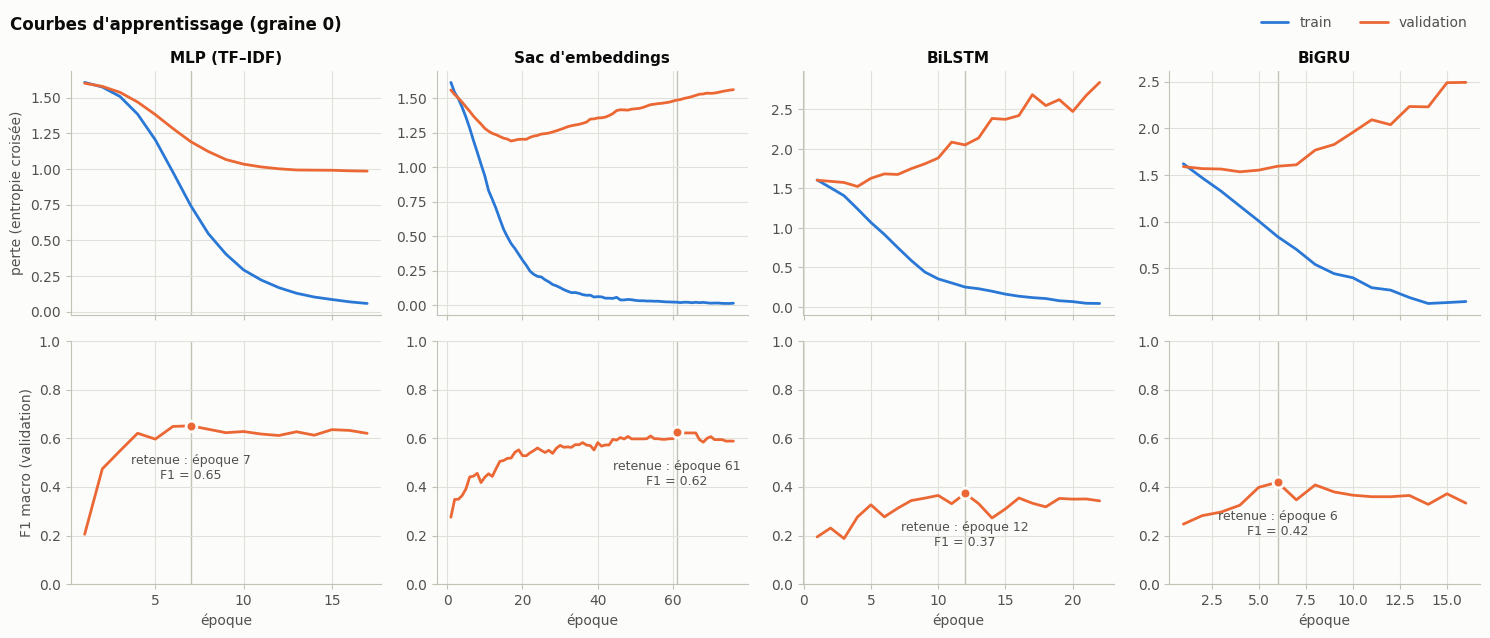

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharex="col")
for j, (nom, hist) in enumerate(historiques.items()):
    haut, bas = axes[0, j], axes[1, j]
    haut.plot(hist["époque"], hist["perte train"], color=SERIES[0], label="train")
    haut.plot(hist["époque"], hist["perte validation"], color=SERIES[1], label="validation")
    haut.set_title(nom)

    i_best = hist["F1 validation"].idxmax()
    bas.plot(hist["époque"], hist["F1 validation"], color=SERIES[1])
    bas.scatter(hist.loc[i_best, "époque"], hist.loc[i_best, "F1 validation"], s=60,
                color=SERIES[1], edgecolor=SURFACE, linewidth=2, zorder=3)
    bas.annotate(f"retenue : époque {hist.loc[i_best, 'époque']}\nF1 = {hist.loc[i_best, 'F1 validation']:.2f}",
                 xy=(hist.loc[i_best, "époque"], hist.loc[i_best, "F1 validation"]),
                 xytext=(0, -38), textcoords="offset points", ha="center", color=INK2, fontsize=9)
    bas.set_ylim(0, 1)
    bas.set_xlabel("époque")
    for ax in (haut, bas):
        ax.axvline(hist.loc[i_best, "époque"], color=AXE, linewidth=1, zorder=0)

axes[0, 0].set_ylabel("perte (entropie croisée)")
axes[1, 0].set_ylabel("F1 macro (validation)")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("Courbes d'apprentissage (graine 0)", x=0.01, ha="left", fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

> **Lecture des courbes : le sur-apprentissage, en direct.**
>
> - **La perte d'entraînement tend vers 0 pour tous les réseaux.** Le BiLSTM et le BiGRU y arrivent en une quinzaine d'époques : ils ont mémorisé les 516 répliques. (La perte train est mesurée avec le dropout actif, ce qui la rend un peu bruitée.)
> - **La perte de validation remonte presque tout de suite pour les RNN**, dès les époques 3 à 5, pendant que leur F1 de validation plafonne autour de 0,40. C'est la signature d'une **variance élevée** (slide 26) : le modèle apprend des détails propres au train qui ne se retrouvent pas ailleurs.
> - **Pour le MLP**, la perte de validation se stabilise vers 1,0 et le meilleur F1 est atteint très tôt, dès l'époque 7.
> - **Pour le sac d'embeddings**, la perte de validation remonte après l'époque 18 alors que le F1 continue de progresser jusqu'à l'époque 63. Le modèle devient **trop confiant** sur ses erreurs (la perte, qui pénalise une mauvaise réponse donnée avec assurance, augmente), tout en se trompant de moins en moins souvent. C'est pour cela que l'arrêt précoce surveille ici le F1, la métrique qui nous intéresse, plutôt que la perte.
>
> L'arrêt précoce garde les poids de la meilleure époque (trait vertical) : il limite les dégâts du sur-apprentissage, mais ne peut pas créer l'information que les données ne contiennent pas.

## 7. Évaluation finale sur le test

Tous les choix sont faits — hyperparamètres ML, architecture, époque d'arrêt — sans avoir regardé le test. On l'ouvre maintenant, une seule fois.

### 7.1 Tableau comparatif

In [16]:
def metriques(y_vrai, y_pred):
    return {
        "accuracy": accuracy_score(y_vrai, y_pred),
        "précision (macro)": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "rappel (macro)": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
    }


def n_parametres_ml(m):
    attributs = ["coef_", "intercept_", "feature_log_prob_", "class_log_prior_"]
    return int(sum(getattr(m, a).size for a in attributs if hasattr(m, a)))


preds_test, lignes = {}, []
for nom, m in modeles_ml.items():
    preds_test[nom] = m.predict(Xte_tfidf)
    lignes.append({"modèle": nom, "famille": "ML", **metriques(yte, preds_test[nom]),
                   "σ F1 macro (5 graines)": np.nan, "paramètres": n_parametres_ml(m),
                   "entraînement (s)": durees_ml.get(nom, 0.0)})

for nom, cfg in ARCHITECTURES.items():
    par_graine = []
    for g in GRAINES:
        preds_test[(nom, g)], _ = predire(modeles_dl[(nom, g)], P[cfg["entree"]]["test"])
        par_graine.append(metriques(yte, preds_test[(nom, g)]))
    par_graine = pd.DataFrame(par_graine)
    lignes.append({"modèle": nom, "famille": "DL", **par_graine.mean().to_dict(),
                   "σ F1 macro (5 graines)": par_graine["F1 (macro)"].std(),
                   "paramètres": n_parametres(modeles_dl[(nom, 0)]),
                   "entraînement (s)": resume.loc[resume["modèle"] == nom, "durée (s)"].mean()})

tableau = pd.DataFrame(lignes).set_index("modèle").sort_values("F1 (macro)", ascending=False)
print("Modèles DL : moyenne des métriques sur 5 graines.")
tableau.round(3)

Modèles DL : moyenne des métriques sur 5 graines.


,famille,accuracy,précision (macro),rappel (macro),F1 (macro),F1 (weighted),σ F1 macro (5 graines),paramètres,entraînement (s)
modèle,,,,,,,,,
Naive Bayes,ML,0.667,0.683,0.660,0.662,0.664,NaN,14795,0.001
MLP (TF–IDF),DL,0.660,0.665,0.664,0.660,0.661,0.016,758789,1.929
SVM linéaire,ML,0.634,0.636,0.635,0.633,0.635,NaN,14795,0.021
Régression logistique,ML,0.634,0.636,0.629,0.632,0.634,NaN,14795,0.732
Sac d'embeddings,DL,0.599,0.597,0.598,0.593,0.599,0.025,89093,2.636
BiLSTM,DL,0.420,0.423,0.417,0.414,0.416,0.022,224337,6.000
BiGRU,DL,0.395,0.404,0.398,0.395,0.394,0.026,203089,4.631
Baseline (classe majoritaire),ML,0.261,0.052,0.200,0.083,0.108,NaN,0,0.000


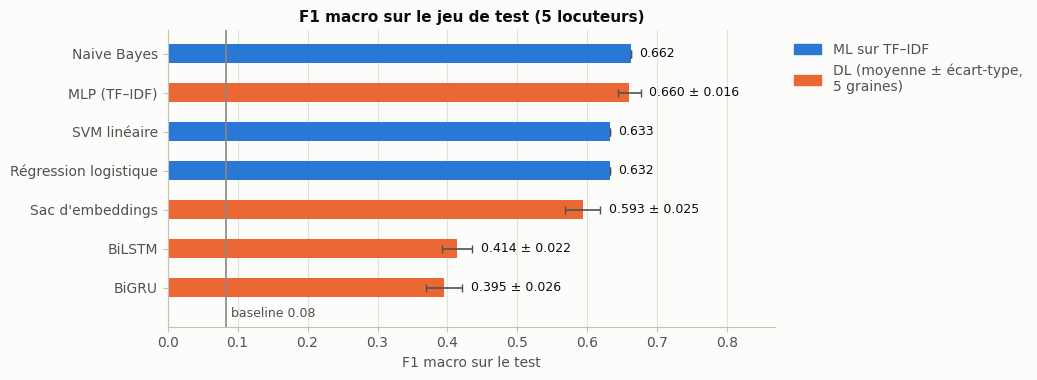

In [17]:
t = tableau.drop(index="Baseline (classe majoritaire)").sort_values("F1 (macro)")
y = np.arange(len(t))
sigma = t["σ F1 macro (5 graines)"].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(10.5, 3.9))
ax.barh(y, t["F1 (macro)"], height=0.5,
        color=[SERIES[0] if f == "ML" else SERIES[1] for f in t["famille"]])
ax.errorbar(t["F1 (macro)"], y, xerr=sigma, fmt="none", ecolor=INK2, elinewidth=1.2, capsize=3)
for yi, (v, s, fam) in enumerate(zip(t["F1 (macro)"], sigma, t["famille"])):
    etiquette = f"{v:.3f}" + (f" ± {s:.3f}" if fam == "DL" else "")
    ax.text(v + s + 0.012, yi, etiquette, va="center", color=INK, fontsize=9)

base = tableau.loc["Baseline (classe majoritaire)", "F1 (macro)"]
ax.axvline(base, color=MUTED, linewidth=1.2)
ax.text(base + 0.008, -0.75, f"baseline {base:.2f}", color=INK2, fontsize=9)

ax.set_yticks(y, t.index)
ax.set_xlim(0, min(1, t["F1 (macro)"].max() + sigma.max() + 0.18))
ax.set_ylim(-1, len(t) - 0.4)
ax.set_xlabel("F1 macro sur le test")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=SERIES[0], label="ML sur TF–IDF"),
                   Patch(color=SERIES[1], label="DL (moyenne ± écart-type,\n5 graines)")],
          loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set_title("F1 macro sur le jeu de test (5 locuteurs)")
plt.tight_layout()
plt.show()

> **Lecture du tableau : sur 516 répliques, le deep learning ne bat pas le machine learning classique.**
>
> 1. **Naive Bayes arrive en tête (F1 macro 0,662), à égalité avec le MLP (0,655 ± 0,008).** L'écart de 0,007 est inférieur à l'écart-type du MLP entre graines. Sur 153 répliques de test, une seule réponse de plus ou de moins fait bouger le F1 d'environ 0,007 : on ne peut pas départager ces deux modèles.
> 2. **Le MLP fait aussi bien que les modèles linéaires parce qu'il reçoit la même information** : le même vecteur TF–IDF. Sa non-linéarité n'apporte rien de mesurable ici, et elle coûte 50 fois plus de paramètres.
> 3. **Lire l'ordre des mots coûte cher et ne rapporte rien ici.** Le BiLSTM (0,444) et le BiGRU (0,424) sont environ 0,22 sous Naive Bayes, et leur entraînement est plus de 20 000 fois plus long (≈ 55 s contre 2 ms). Quatre raisons se cumulent :
>    - **trop peu de données** : 516 exemples pour plus de 200 000 paramètres, d'où la mémorisation vue sur les courbes ;
>    - des **embeddings partis de zéro**, avec 16 % de mots inconnus au test ;
>    - le **goulot du dernier état** : toute la réplique doit tenir dans le vecteur final $h_T$. Dans une tirade de 100 tokens, un nom propre placé au milieu (l'indice décisif, selon le TP 1) se dilue, alors que TF–IDF le garde intact ;
>    - une **tâche lexicale** : ce qui distingue ces personnages, c'est *quels mots* ils emploient et *qui* ils nomment, beaucoup plus que l'ordre dans lequel ils les disent.
> 4. **Le sac d'embeddings (0,572)** se place entre les deux : il ignore l'ordre comme TF–IDF, mais doit apprendre ses vecteurs à partir de zéro, sans bigrammes ni pondération IDF.
> 5. **La régression logistique obtient ici 0,632, contre 0,669 au TP 1.** Elle s'entraîne sur 92 répliques de moins (prélevées pour la validation), et son `C` est choisi sans regarder le test. Cet écart de 0,04 montre à quel point le score dépend du volume de données à cette échelle (voir 8.5).
>
> C'est la bonne pratique de la slide 15 vérifiée sur un cas réel : **établir d'abord une baseline simple, puis n'ajouter de la complexité que si le gain mesuré la justifie.** Ici, il ne la justifie pas.

### 7.2 Résultats par locuteur et matrices de confusion

On compare le meilleur modèle ML et le meilleur réseau, **tous deux désignés sur la validation**. Pour le réseau, les valeurs sont des moyennes sur les 5 graines (d'où les décimales dans sa matrice de confusion).

F1 par locuteur sur le test
                Naive Bayes  MLP (TF–IDF) (moy. 5 graines)  exemples de test
DUKE VINCENTIO        0.675                          0.662                33
GLOUCESTER            0.691                          0.674                40
MENENIUS              0.679                          0.673                25
PETRUCHIO             0.681                          0.672                27
ROMEO                 0.583                          0.617                28 



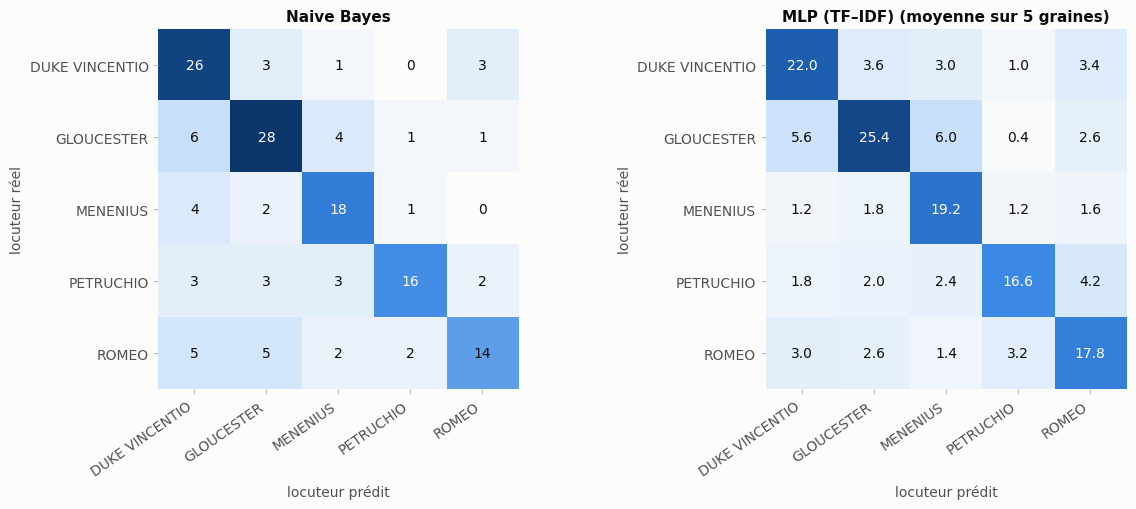

In [18]:
f1_par_classe = pd.DataFrame({
    meilleur_ml: f1_score(yte, preds_test[meilleur_ml], average=None),
    f"{meilleur_dl} (moy. 5 graines)": np.mean(
        [f1_score(yte, preds_test[(meilleur_dl, g)], average=None) for g in GRAINES], axis=0),
    "exemples de test": np.bincount(yte, minlength=K),
}, index=CLASSES)
print("F1 par locuteur sur le test")
print(f1_par_classe.round(3).to_string(), "\n")

cm_ml = confusion_matrix(yte, preds_test[meilleur_ml], labels=range(K))
cm_dl = np.mean([confusion_matrix(yte, preds_test[(meilleur_dl, g)], labels=range(K)) for g in GRAINES], axis=0)
carte = LinearSegmentedColormap.from_list("bleu", RAMPE_BLEUE)
vmax = max(cm_ml.max(), cm_dl.max())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for ax, cm, titre, fmt in [(axes[0], cm_ml, meilleur_ml, "{:.0f}"),
                           (axes[1], cm_dl, f"{meilleur_dl} (moyenne sur 5 graines)", "{:.1f}")]:
    ax.imshow(cm, cmap=carte, vmin=0, vmax=vmax)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, fmt.format(cm[i, j]), ha="center", va="center", fontsize=10,
                    color="#ffffff" if cm[i, j] > 0.55 * vmax else INK)
    ax.set_xticks(range(K), CLASSES, rotation=35, ha="right")
    ax.set_yticks(range(K), CLASSES)
    ax.set_xlabel("locuteur prédit")
    ax.set_ylabel("locuteur réel")
    ax.set_title(titre)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
plt.tight_layout()
plt.show()

> **Lecture.**
>
> - Les deux modèles ont des profils très proches. Roméo est le locuteur le plus difficile pour Naive Bayes (F1 0,58) ; le MLP fait un peu mieux sur lui (0,61), un peu moins bien sur les autres.
> - **Les confusions dominantes sont les mêmes pour les deux modèles** : Gloucester est confondu avec le duc Vincentio (6 erreurs pour Naive Bayes, 5,8 en moyenne pour le MLP) et avec Ménénius (4 et 5,2). Ce sont les trois personnages « politiques » : un duc qui gouverne Vienne, un patricien de Rome, un prétendant à la couronne. Ils partagent le vocabulaire du pouvoir (*lord*, *state*, *people*).
> - Gloucester est aussi la classe la plus fréquente (40 répliques de test) : il « attire » les répliques ambiguës.
> - Pour le MLP, Petruchio est souvent pris pour Roméo (4,2) : deux jeunes premiers qui parlent de cœur et de mariage.

## 8. Analyse

### 8.1 Les réseaux sont instables d'une graine à l'autre

In [19]:
f1_graines = pd.DataFrame(
    {nom: [f1_score(yte, preds_test[(nom, g)], average="macro") for g in GRAINES] for nom in ARCHITECTURES},
    index=[f"graine {g}" for g in GRAINES],
)
resume_graines = pd.DataFrame({"moyenne": f1_graines.mean(), "écart-type": f1_graines.std(),
                               "min": f1_graines.min(), "max": f1_graines.max()}).T
print("F1 macro sur le test, graine par graine")
pd.concat([f1_graines, resume_graines]).round(3)

F1 macro sur le test, graine par graine


,MLP (TF–IDF),Sac d'embeddings,BiLSTM,BiGRU
graine 0,0.661,0.588,0.412,0.358
graine 1,0.679,0.586,0.448,0.417
graine 2,0.659,0.574,0.398,0.406
graine 3,0.634,0.637,0.393,0.377
graine 4,0.666,0.581,0.417,0.415
moyenne,0.660,0.593,0.414,0.395
écart-type,0.016,0.025,0.022,0.026
min,0.634,0.574,0.393,0.358
max,0.679,0.637,0.448,0.417


> **Lecture.** Le MLP est stable : 0,646 à 0,664 selon la graine. Le **BiLSTM varie de 0,410 à 0,484** selon la seule initialisation aléatoire, soit 0,07 d'écart. Avec un seul entraînement, on aurait pu conclure que le BiLSTM bat nettement le BiGRU, ou l'inverse.
>
> Pour un réseau de neurones, **un score n'a de sens qu'accompagné de sa dispersion**. C'est la version deep learning du conseil du TP 1 : « un modèle à 0,82 ± 0,01 vaut souvent mieux qu'un modèle à 0,84 ± 0,09 ».

### 8.2 Le réseau et le modèle linéaire se trompent-ils sur les mêmes répliques ?

On compare les prédictions du meilleur modèle ML et du meilleur réseau (graine 0, fixée avant de voir les résultats).

In [20]:
p_ml, p_dl = preds_test[meilleur_ml], preds_test[(meilleur_dl, 0)]
ok_ml, ok_dl = p_ml == yte, p_dl == yte

print(pd.crosstab(pd.Series(np.where(ok_ml, "juste", "faux"), name=meilleur_ml),
                  pd.Series(np.where(ok_dl, "juste", "faux"), name=meilleur_dl)), "\n")
print(f"Même prédiction pour les deux modèles : {np.mean(p_ml == p_dl):.0%} du test")
print(f"Au moins un des deux a raison         : {np.mean(ok_ml | ok_dl):.0%}  (borne haute d'une combinaison des deux)\n")


def montrer(masque, titre, n=3):
    print(titre)
    for i in np.where(masque)[0][:n]:
        r = X_test.iloc[i]
        print(f"  vrai : {CLASSES[yte[i]]:<15} {meilleur_ml} : {CLASSES[p_ml[i]]:<15} {meilleur_dl} : {CLASSES[p_dl[i]]}")
        print(f"  « {r[:170]}{'…' if len(r) > 170 else ''} »\n")


montrer(ok_dl & ~ok_ml, f"--- {meilleur_dl} a raison, {meilleur_ml} se trompe ---")
montrer(ok_ml & ~ok_dl, f"--- {meilleur_ml} a raison, {meilleur_dl} se trompe ---")

MLP (TF–IDF)  faux  juste
Naive Bayes              
faux            46      5
juste            6     96 

Même prédiction pour les deux modèles : 85% du test
Au moins un des deux a raison         : 70%  (borne haute d'une combinaison des deux)

--- MLP (TF–IDF) a raison, Naive Bayes se trompe ---
  vrai : ROMEO           Naive Bayes : GLOUCESTER      MLP (TF–IDF) : ROMEO
  « I'll tell thee, ere thou ask it me again. I have been feasting with mine enemy, Where on a sudden one hath wounded me, That's by me wounded: both our remedies Within thy … »

  vrai : ROMEO           Naive Bayes : DUKE VINCENTIO  MLP (TF–IDF) : ROMEO
  « I must indeed; and therefore came I hither. Good gentle youth, tempt not a desperate man; Fly hence, and leave me: think upon these gone; Let them affright thee. I beseec… »

  vrai : ROMEO           Naive Bayes : MENENIUS        MLP (TF–IDF) : ROMEO
  « Ha, banishment! be merciful, say 'death;' For exile hath more terror in his look, Much more than death: do not s

> **Lecture.**
>
> - Naive Bayes et le MLP donnent **la même réponse sur 86 % des répliques**. Les cas où un seul des deux a raison sont rares : 5 répliques sur 153 où seul le MLP a raison, 6 où seul Naive Bayes a raison.
> - Même en choisissant après coup, pour chaque réplique, le modèle qui a raison (l'« oracle »), on ne dépasserait pas 70 % d'accuracy, contre 67 % pour Naive Bayes seul. Combiner les deux rapporterait donc au mieux 3 points.
> - Ils commettent les mêmes erreurs parce qu'ils lisent **le même signal**, le vecteur TF–IDF, et le pondèrent seulement un peu différemment. Les trois répliques que seul le MLP reconnaît sont de longues tirades de Roméo, au vocabulaire très marqué (*banishment*, *desperate man*). Celles que seul Naive Bayes reconnaît sont des phrases plus neutres.
>
> Pour qu'un ensemble de modèles soit utile, il faut des modèles qui se trompent **différemment** : par exemple un modèle à base de mots et un modèle qui exploite une autre source d'information.

### 8.3 Qu'ont appris les embeddings ?

Le cours montre des embeddings où des mots de sens proche ont des directions proches (slides 18–22). Regardons les plus proches voisins (similarité cosinus) de quelques mots dans la matrice d'embeddings apprise par le sac d'embeddings, ainsi que le locuteur vers lequel chaque mot « pousse » la décision (le score le plus élevé que la couche de sortie donne au vecteur du mot seul).

In [21]:
modele_sac = modeles_dl[("Sac d'embeddings", 0)].cpu()
E = modele_sac.emb.weight.detach()
E_norm = nn.functional.normalize(E, dim=1)
vote = (modele_sac.sortie(E)).argmax(1)        # locuteur favorisé par chaque mot pris seul

stoi_P, itos_P = P["stoi"], P["itos"]
for mot in ["love", "lord", "rome", "kate", "king", "sir", "night", "thou"]:
    if mot not in stoi_P:
        continue
    sims = E_norm @ E_norm[stoi_P[mot]]
    voisins = [i for i in sims.argsort(descending=True).tolist() if i > UNK and i != stoi_P[mot]][:6]
    print(f"{mot:<6} [{CLASSES[vote[stoi_P[mot]]]:<14}] -> "
          + ", ".join(f"{itos_P[i]} [{CLASSES[vote[i]]}]" for i in voisins))
modeles_dl[("Sac d'embeddings", 0)].to(device);

love   [ROMEO         ] -> amen [ROMEO], capulet [ROMEO], comfort [ROMEO], adieu [ROMEO], own [ROMEO], kinsman [ROMEO]
lord   [GLOUCESTER    ] -> cousin [GLOUCESTER], marry [GLOUCESTER], believe [GLOUCESTER], myself [GLOUCESTER], seldom [DUKE VINCENTIO], minds [GLOUCESTER]
rome   [MENENIUS      ] -> menenius [MENENIUS], state [MENENIUS], brain [MENENIUS], people [MENENIUS], affection [MENENIUS], discontented [MENENIUS]
kate   [PETRUCHIO     ] -> hortensio [PETRUCHIO], goods [PETRUCHIO], field [PETRUCHIO], grumio [PETRUCHIO], woo [PETRUCHIO], feast [PETRUCHIO]
king   [GLOUCESTER    ] -> clarence [GLOUCESTER], castle [GLOUCESTER], edward [GLOUCESTER], paul [GLOUCESTER], thereof [GLOUCESTER], endure [GLOUCESTER]
sir    [PETRUCHIO     ] -> toward [PETRUCHIO], feast [PETRUCHIO], barber's [PETRUCHIO], leisure [PETRUCHIO], young [PETRUCHIO], wretch [DUKE VINCENTIO]
night  [ROMEO         ] -> lark [ROMEO], mercutio [ROMEO], hence [ROMEO], east [ROMEO], saw [ROMEO], vile [ROMEO]
thou   [ROMEO  

> **Lecture : les embeddings ont appris la tâche, pas le sens.**
>
> Les plus proches voisins ne sont pas des synonymes. *love* a pour voisins *comfort, amen, capulet, says, hers, adieu* ; *lord* a pour voisins *cousin, marry, minds, simple, clarence, myself*. Le point commun de chaque liste : **presque tous les mots « votent » pour le même personnage** que le mot de départ. *rome* est entouré de mots de Ménénius, *kate* de mots de Petruchio, *night* de mots de Roméo.
>
> C'est logique. Le seul signal d'apprentissage était « qui parle ? ». Les vecteurs se sont donc organisés selon cet axe : deux mots sont proches s'ils désignent le même locuteur, quel que soit leur sens.
>
> Les embeddings des slides 18 à 22 (*roi − homme + femme ≈ reine*) sont d'une autre nature. Ils viennent d'un apprentissage **auto-supervisé** sur des milliards de mots, où le signal est « quel mot va avec quel contexte ? ». 516 répliques étiquetées ne peuvent pas produire ce genre de géométrie. C'est l'argument central du **pré-entraînement** des Transformers : apprendre d'abord le sens sur un énorme corpus non annoté, puis l'adapter à la tâche.

### 8.4 Le réseau échappe-t-il au raccourci des noms propres ?

Le corrigé du TP 1 a montré que la régression logistique reconnaît surtout la **pièce** (via les noms propres) plutôt que le style du personnage. Le meilleur réseau (choisi sur la validation) échappe-t-il à ce raccourci ?

On refait l'expérience avec une heuristique plus précise que celle du TP 1 : un mot est considéré comme nom propre s'il apparaît **avec une majuscule mais jamais en minuscules** dans tout le corpus (`Kate`, `Rome`, `Clarence`…). L'heuristique du TP 1 retirait aussi les mots ordinaires placés en début de vers (`What`, `And`…), ce qui exagérait la chute.

Les noms propres sont retirés **à l'entraînement et au test**, pour les deux modèles, et le vocabulaire est reconstruit sans eux.

In [22]:
capitalises = set(re.findall(r"\b[A-Z][a-z]+\b", texte))
minuscules = set(re.findall(r"\b[a-z]+\b", texte))
noms_propres = {m.lower() for m in capitalises if m.lower() not in minuscules}

frequents = Counter(m for t in X_train for m in tokeniser(t) if m in noms_propres).most_common(15)
print(f"{len(noms_propres):,} noms propres détectés. Les plus fréquents dans le train :")
print("  " + ", ".join(f"{m} ({c})" for m, c in frequents), "\n")


def tokeniser_sans_noms(texte):
    return [m for m in tokeniser(texte) if m not in noms_propres]


P_sans = preparer(X_train, ytr, tok=tokeniser_sans_noms, mots_exclus=sorted(noms_propres))

# Modèle ML : même hyperparamètre que celui retenu sur la validation
ml_sans = grilles[meilleur_ml][0](modeles_ml[meilleur_ml].get_params()[grilles[meilleur_ml][1]])
ml_sans.fit(P_sans["vec"].transform(X_train), ytr)
f1_ml_sans = f1_score(yte, ml_sans.predict(P_sans["vec"].transform(X_test)), average="macro")

f1_dl_sans = []
for g in GRAINES:
    m, _, _ = entrainer_dl(meilleur_dl, P_sans, g)
    pred, _ = predire(m, P_sans[ARCHITECTURES[meilleur_dl]["entree"]]["test"])
    f1_dl_sans.append(f1_score(yte, pred, average="macro"))

avec = {meilleur_ml: tableau.loc[meilleur_ml, "F1 (macro)"], meilleur_dl: tableau.loc[meilleur_dl, "F1 (macro)"]}
sans = {meilleur_ml: f1_ml_sans, meilleur_dl: np.mean(f1_dl_sans)}
pd.DataFrame({
    "F1 macro avec noms propres": avec,
    "F1 macro sans noms propres": sans,
    "variation relative": {k: sans[k] / avec[k] - 1 for k in avec},
}).round(3)

900 noms propres détectés. Les plus fréquents dans le train :
  kate (45), angelo (26), clarence (15), edward (10), juliet (9), marcius (8), hortensio (7), rome (7), mercutio (6), tybalt (6), claudio (5), coriolanus (5), henry (5), paul (5), cominius (5) 



,F1 macro avec noms propres,F1 macro sans noms propres,variation relative
Naive Bayes,0.662,0.600,-0.094
MLP (TF–IDF),0.660,0.597,-0.095


> **Lecture.**
>
> - L'heuristique trouve 900 noms propres dans le corpus. Les plus fréquents dans le train sont bien des personnages et des lieux propres à une pièce : *kate* (45 occurrences), *angelo*, *clarence*, *edward*, *juliet*, *marcius*, *hortensio*, *rome*…
> - Le meilleur réseau sur la validation est le **MLP**. Sans les noms propres, il perd 8 % de son F1 (0,655 → 0,601), presque autant que Naive Bayes (−9 %, 0,662 → 0,600). **Le réseau apprend le même raccourci que le modèle linéaire** : il reçoit la même entrée et n'a aucune raison de l'ignorer.
> - **La chute est bien plus faible que les −37 % du TP 1.** L'heuristique du TP 1 retirait tout mot écrit avec une majuscule, donc aussi les mots ordinaires en début de vers (*What*, *And*, *The*…), et le modèle perdait une grande partie de son vocabulaire. Mesuré plus proprement, le raccourci des noms propres pèse **environ 10 % du score**.
> - Le reste du signal n'est pas pour autant du « style » pur. Des noms communs propres à chaque pièce (*tribunes*, *consul*, *provost*, *friar*) restent dans le vocabulaire et désignent encore la pièce plutôt que le personnage.
>
> C'est une leçon de méthode autant que de NLP : **la conclusion d'une expérience dépend de la qualité de l'outil de mesure**.

### 8.5 Le deep learning manque-t-il de données ?

Le cours annonce que les réseaux ont besoin de beaucoup de données (slide 39). On le vérifie avec une **courbe d'apprentissage** : chaque modèle est réentraîné sur 25 %, 50 %, 75 % puis 100 % du train (sous-échantillons stratifiés). À chaque taille, TF–IDF, vocabulaire et poids des classes sont recalculés sur le sous-échantillon. On compare le meilleur modèle ML, le MLP (même entrée TF–IDF, mais non linéaire) et le meilleur réseau à embeddings.

Le test sert ici à analyser, pas à choisir : aucune décision n'est prise à partir de ces courbes.

modèle  Naive Bayes  MLP (TF–IDF)  Sac d'embeddings
n                                                  
129           0.504         0.486             0.436
258           0.542         0.588             0.502
387           0.617         0.623             0.578
516           0.662         0.667             0.583


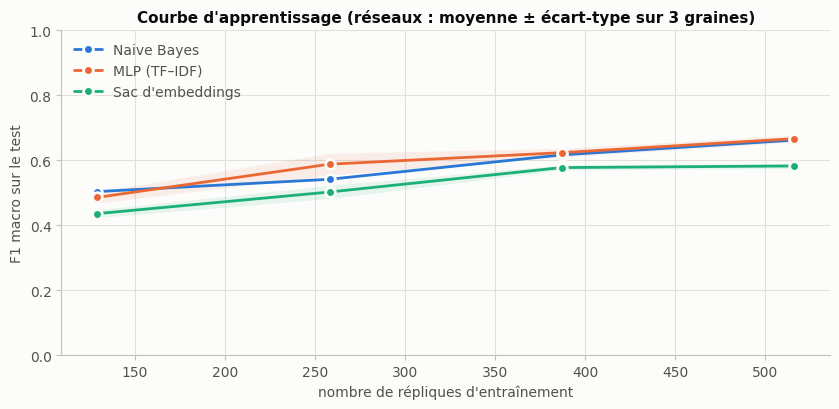

In [23]:
reseau_seq = (resume[resume["modèle"] != "MLP (TF–IDF)"]
              .groupby("modèle")["F1 validation"].mean().idxmax())
MODELES_COURBE = [meilleur_ml, "MLP (TF–IDF)", reseau_seq]
FRACTIONS = [0.25, 0.5, 0.75, 1.0]
GRAINES_COURBE = GRAINES[:3]

points = []
for frac in FRACTIONS:
    if frac < 1:
        X_sub, _, y_sub, _ = train_test_split(X_train, ytr, train_size=frac, stratify=ytr,
                                              random_state=RANDOM_STATE)
    else:
        X_sub, y_sub = X_train, ytr
    P_sub = preparer(X_sub, y_sub)

    ml = grilles[meilleur_ml][0](modeles_ml[meilleur_ml].get_params()[grilles[meilleur_ml][1]])
    ml.fit(P_sub["vec"].transform(X_sub), y_sub)
    points.append({"n": len(X_sub), "modèle": meilleur_ml,
                   "F1": f1_score(yte, ml.predict(P_sub["vec"].transform(X_test)), average="macro")})

    for nom in MODELES_COURBE[1:]:
        for g in GRAINES_COURBE:
            m, _, _ = entrainer_dl(nom, P_sub, g)
            pred, _ = predire(m, P_sub[ARCHITECTURES[nom]["entree"]]["test"])
            points.append({"n": len(X_sub), "modèle": nom, "F1": f1_score(yte, pred, average="macro")})

courbe = pd.DataFrame(points).groupby(["modèle", "n"])["F1"].agg(["mean", "std"]).reset_index()
print(courbe.pivot(index="n", columns="modèle", values="mean")[MODELES_COURBE].round(3).to_string())

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for couleur, nom in zip(SERIES, MODELES_COURBE):
    c = courbe[courbe["modèle"] == nom]
    ax.plot(c["n"], c["mean"], color=couleur, marker="o", markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2, label=nom)
    if c["std"].notna().any():
        ax.fill_between(c["n"], c["mean"] - c["std"], c["mean"] + c["std"], color=couleur, alpha=0.10, linewidth=0)
ax.set_xlabel("nombre de répliques d'entraînement")
ax.set_ylabel("F1 macro sur le test")
ax.set_ylim(0, 1)
ax.set_xlim(courbe["n"].min() - 20, courbe["n"].max() + 20)
ax.legend(loc="upper left")
ax.set_title("Courbe d'apprentissage (réseaux : moyenne ± écart-type sur 3 graines)")
plt.tight_layout()
plt.show()

> **Lecture.**
>
> - **Tous les modèles progressent avec les données, et aucune courbe n'est encore plate à 516 répliques.** Plus de données aideraient tout le monde.
> - **Les réseaux progressent plus vite.** De 129 à 516 répliques, Naive Bayes gagne +0,16 de F1, le MLP et le sac d'embeddings environ +0,22.
> - **Naive Bayes est le meilleur quand les données sont rares** : 0,50 avec 129 répliques, contre 0,43 pour le MLP et 0,34 pour le sac d'embeddings. C'est sa réputation (slide 32 : « peu de données, baseline efficace »). Le MLP le rattrape dès 258 répliques (0,57 contre 0,54), puis les deux restent au coude à coude.
> - **Le sac d'embeddings ne progresse presque plus** entre 387 et 516 répliques (0,56 dans les deux cas) : avec un vocabulaire aussi petit, il n'apprend plus grand-chose de nouveau.
>
> Extrapoler est risqué, mais la tendance est celle qu'annonce le cours (slide 39) : l'avantage du deep learning ne peut apparaître qu'avec **beaucoup plus de données**. Or ce corpus ne contient que 761 répliques pour ces 5 personnages : on ne peut pas en obtenir plus. C'est exactement la situation où l'on part d'un **modèle pré-entraîné** sur un grand corpus, que l'on adapte ensuite à la tâche (*transfer learning*, séances 3 et 4).

## 9. Synthèse

**Réponse à la question du TP.** Sur cette tâche et avec ces données, un réseau de neurones ne fait **pas mieux** qu'un modèle linéaire sur TF–IDF. Il fait au mieux **aussi bien** (le MLP), pour un coût d'entraînement et une complexité bien supérieurs.

| Modèle | F1 macro (test) | Entraînement | Paramètres |
|---|---|---|---|
| Naive Bayes (TF–IDF) | **0,662** | 2 ms | 14 795 |
| MLP (TF–IDF) | 0,655 ± 0,008 | ≈ 2,5 s | 758 789 |
| Régression logistique (TF–IDF) | 0,632 | 0,15 s | 14 795 |
| Sac d'embeddings | 0,572 ± 0,020 | ≈ 3 s | 89 093 |
| BiLSTM | 0,444 ± 0,032 | ≈ 55 s | 224 337 |
| BiGRU | 0,424 ± 0,009 | ≈ 55 s | 203 089 |
| *Baseline (classe majoritaire)* | *0,083* | — | — |

*Valeurs de notre exécution sur CPU ; temps par entraînement.*

**Les cinq messages à retenir**

1. **Le meilleur modèle dépend des données, pas de la mode.** Avec 516 exemples, la baseline simple reste la référence à battre (slide 15).
2. **Plus de capacité, c'est plus de mémorisation.** Les RNN apprennent le train par cœur en une quinzaine d'époques. L'arrêt précoce et le dropout limitent les dégâts, sans compenser le manque de données.
3. **Un score de réseau se donne avec sa dispersion.** Selon la graine, le BiLSTM varie de 0,41 à 0,48.
4. **Des embeddings appris sur une tâche encodent la tâche, pas le sens.** Les nôtres regroupent les mots par personnage. Des embeddings sémantiques demandent un pré-entraînement auto-supervisé massif.
5. **Le deep learning a besoin de données.** Ses courbes d'apprentissage montent plus vite que celles du modèle classique, mais ne le dépassent pas à 516 exemples. La solution n'est pas un réseau plus gros, mais un réseau **déjà entraîné** ailleurs.

**Ce que cela annonce.** Les deux faiblesses observées, des mots inconnus et des embeddings sans sens, sont précisément ce que résolvent les **Transformers pré-entraînés** : tokenisation en sous-mots, représentations contextualisées apprises sur des milliards de tokens, puis adaptation à la tâche par fine-tuning (le notebook CamemBERT du cours) ou par simple **prompting** (TP 3).

## 10. Pour aller plus loin

- **Embeddings pré-entraînés.** Initialiser la couche d'embedding avec des vecteurs appris sur un grand corpus (GloVe, fastText) au lieu de partir de zéro. C'est la réponse directe au manque de données observé en 8.5.
- **Fine-tuning d'un Transformer.** Remplacer le BiLSTM par un encodeur pré-entraîné (BERT, RoBERTa) et l'ajuster sur la tâche, comme dans le notebook de fine-tuning de CamemBERT fourni avec le cours. C'est le sujet des séances 3 et 4.
- **Combiner les deux familles.** La partie 8.2 montre que les deux modèles ne se trompent pas toujours sur les mêmes répliques : une moyenne de leurs probabilités peut dépasser chacun d'eux.
- **Une tâche qui exige l'ordre des mots.** Retirer les noms propres rend la tâche plus proche d'une vraie reconnaissance de style. Comparer à nouveau régression logistique et BiLSTM dans ce cadre, avec davantage de locuteurs.